In [1]:
no_of_threads = "12"

import os
os.environ["VECLIB_MAXIMUM_THREADS"] = no_of_threads
os.environ["OMP_NUM_THREADS"] = no_of_threads


In [2]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [3]:
B=16 #Batchsize

In [4]:


import torch
from torch import linalg as LA
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import time
import statistics
from typing import Tuple
from typing_extensions import Annotated
import transformers
import psutil

from transformers import AutoModelForCausalLM, AutoTokenizer
import json
import platform
import subprocess
import time
from datasets import load_dataset
import re

In [5]:
arc = load_dataset("allenai/ai2_arc", "ARC-Challenge", split="test")

In [6]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
REVISION = "989aa7980e4cf806f80c7fef2b1adb7bc71aa306"   

#model_hf = AutoModelForCausalLM.from_pretrained(
#    MODEL_ID, revision=REVISION, dtype=torch.float32, device_map="cpu"
#)

model_hf = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, dtype=torch.float32
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)

W1029 22:38:59.230000 57443 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

In [7]:


def extract_letter(text):
   
    for pat in (r"answer is\s*:?\s*\(?([A-E1-5])\b",  
                r"^\s*\(?([A-E1-5])[\).:]",           
                r"\b([A-E1-5])[\).]"):                
        m = re.search(pat, text, re.I | re.M)
        if m:
            return m.group(1).upper()
    return None

tokenizer.padding_side = "left"
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def time_counter(no_of_threads: int, model, tokenizer, prompts: list, results: list,
                 answer_keys: list = None, max_new_tokens: int = 128,
                 batch_size: int = B, repeats: int = 3):

    torch.set_num_threads(int(no_of_threads))
    print("threads:", torch.get_num_threads())
    time.sleep(2)
    proc = psutil.Process(os.getpid())

    for start in range(0, len(prompts), batch_size):
        ids = list(range(start, min(start + batch_size, len(prompts))))
        texts = [tokenizer.apply_chat_template([{"role": "user", "content": prompts[i]}],
                                               tokenize=False, add_generation_prompt=True)
                 for i in ids]
        
        
        model_inputs = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
        print(model_inputs["input_ids"][:, :5])
        print(tokenizer.pad_token_id)
        input_len = model_inputs["input_ids"].shape[1]

        with torch.inference_mode():
            # warm-up (not timed)
            model.generate(**model_inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.pad_token_id)

            n_lst = []
            for i in range(repeats):
                start_time = time.perf_counter()
                out_put_ids = model.generate(**model_inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.pad_token_id)
                end_time = time.perf_counter()
                n_lst.append(end_time - start_time)

        mean = statistics.mean(n_lst)
        stndev = statistics.stdev(n_lst) if len(n_lst) > 1 else 0.0
        mem_gb = proc.memory_info().rss / 1e9
        gen = out_put_ids[:, input_len:]
        n_new = (gen != tokenizer.pad_token_id).sum(dim=1).tolist()
        for row, pid in enumerate(ids):
            answer = tokenizer.decode(gen[row], skip_special_tokens=True)
            letter = extract_letter(answer)
            n_dict = {
                'thread': torch.get_num_threads(),
                'batch_size': batch_size,
                'batch_start': start,
                'prompt_id': pid,
                'batch_mean': mean,
                'batch_stdev': stndev,
                'input_tokens': input_len,
                'new_tokens': n_new[row],
                'mem_gb': mem_gb,
                'answer': answer,
                'pred': letter,
            }
            if answer_keys is not None:
                n_dict['key'] = answer_keys[pid]
                n_dict['correct'] = (letter == answer_keys[pid])
            results.append(n_dict)


        

In [8]:
def make_prompt(item):
    lines = [item["question"]]
    for label, text in zip(item["choices"]["label"], item["choices"]["text"]):
        lines.append(f"{label}. {text}")
    lines.append("Answer with the letter and briefly explain why.")
    return "\n".join(lines)





In [9]:
results = []
prompts = [make_prompt(arc[i]) for i in range(32)]
answer_keys = [arc[i]["answerKey"] for i in range(32)]

with open("prompts_arc32.json", "w") as f:
    json.dump({"prompts": prompts, "answer_keys": answer_keys}, f, indent=2)

with open("prompts_arc32.json") as f:
    data = json.load(f)
prompts, answer_keys = data["prompts"], data["answer_keys"]
print(len(prompts), len(answer_keys))   # 32 32

32 32


In [10]:


run_name = datetime.now().strftime(f"openblas_32p_batch{B}_%Y-%m-%d_%H-%M")  
csv_file = f"{run_name}.csv"
print("saving to", csv_file)

results = []

for t in range(1,13):
    time_counter(t, model_hf, tokenizer, prompts, results, answer_keys=answer_keys)
    pd.DataFrame(results).to_csv(csv_file, index=False)
    print("saved after", t, "threads,", len(results), "rows")
    

saving to openblas_32p_batch16_2026-10-29_22-39.csv
threads: 1
tensor([[151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151644],
        [151644,   8948,    198,   2610,    525],
        [151643, 151643, 151643, 151643, 151644],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643]])
151643
tensor([[151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 1516

In [11]:
results

[{'thread': 1,
  'batch_size': 16,
  'batch_start': 0,
  'prompt_id': 0,
  'batch_mean': 149.92131618066924,
  'batch_stdev': 0.08237893320398569,
  'input_tokens': 148,
  'new_tokens': 128,
  'mem_gb': 7.996604416,
  'answer': "The correct answer is C: Planetary days will become shorter.\n\nExplanation:\nWhen a meteorite impacts a planet, it can cause significant changes to its surface structure and composition. The increased friction from the impact could lead to more frequent collisions between rocks on the planet's surface, which would result in shorter days as the planet slows down due to these collisions. This process is known as tidal locking or synchronous rotation, where one side of the planet always faces the sun, leading to shorter days for that side compared to the other side facing away from the sun.\n\nOptions A (Planetary density will decrease) and B (Planetary years will become",
  'pred': 'C',
  'key': 'C',
  'correct': True},
 {'thread': 1,
  'batch_size': 16,
  'batc

In [12]:
print(torch.__config__.show())

PyTorch built with:
  - GCC 4.2
  - C++ Version: 202002
  - clang 21.1.8
  - OpenMP 202011
  - LAPACK is enabled (usually provided by MKL)
  - NNPACK is enabled
  - CPU capability usage: DEFAULT
  - Build settings: BLAS_INFO=open, BUILD_TYPE=Release, COMMIT_SHA=Unknown, CUDA_FLAGS= -DLIBCUDACXX_ENABLE_SIMPLIFIED_COMPLEX_OPERATIONS -Xfatbin -compress-all  -Wno-deprecated-gpu-targets --expt-extended-lambda -DCUB_WRAPPED_NAMESPACE=at_cuda_detail -DDISABLE_CUSPARSE_DEPRECATED -DCUDA_HAS_FP16=1 -D__CUDA_NO_HALF_OPERATORS__ -D__CUDA_NO_HALF_CONVERSIONS__ -D__CUDA_NO_HALF2_OPERATORS__ -D__CUDA_NO_BFLOAT16_CONVERSIONS__ -DC10_NODEPRECATED, CXX_COMPILER=/Users/runner/miniforge3/conda-bld/libtorch_1791585336308/_build_env/bin/arm64-apple-darwin20.0.0-clang++, CXX_FLAGS=-ftree-vectorize -fPIC -fstack-protector-strong -O2 -pipe -stdlib=libc++  -fmessage-length=0 -isystem /Users/runner/miniforge3/conda-bld/libtorch_1791585336308/_h_env_placehold_placehold_placehold_placehold_placehold_placehold_pla

In [13]:
df = pd.DataFrame(results)
per_batch = df.drop_duplicates(["thread", "batch_start"])        
total = per_batch.groupby("thread")["batch_mean"].sum()          
t1 = total.loc[1]

n_res = []
for n, t in total.items():
    speedup = t1 / t
    n_res.append({
        "threads": n,
        "mean": t,
        "speedup": speedup,
        "efficiency": speedup / n * 100,
        "serial_fraction": ((n / speedup - 1) / (n - 1)) * 100 if n > 1 else None,
    })

In [14]:
n_res

[{'threads': 1,
  'mean': 303.55134809733136,
  'speedup': np.float64(1.0),
  'efficiency': np.float64(100.0),
  'serial_fraction': None},
 {'threads': 2,
  'mean': 164.4383360693464,
  'speedup': np.float64(1.8459889302779047),
  'efficiency': np.float64(92.29944651389523),
  'serial_fraction': np.float64(8.343011553103397)},
 {'threads': 3,
  'mean': 162.618061305664,
  'speedup': np.float64(1.866652115147056),
  'efficiency': np.float64(62.221737171568535),
  'serial_fraction': np.float64(30.35776928267263)},
 {'threads': 4,
  'mean': 162.1844165136766,
  'speedup': np.float64(1.8716431246755056),
  'efficiency': np.float64(46.79107811688764),
  'serial_fraction': np.float64(37.905318723505694)},
 {'threads': 5,
  'mean': 162.63072652802413,
  'speedup': np.float64(1.8665067455443245),
  'efficiency': np.float64(37.33013491088649),
  'serial_fraction': np.float64(41.97002317210837)},
 {'threads': 6,
  'mean': 163.2534072913307,
  'speedup': np.float64(1.8593875198919108),
  'efficie

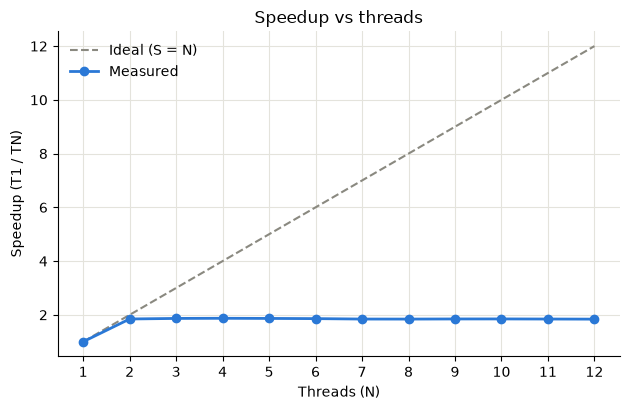

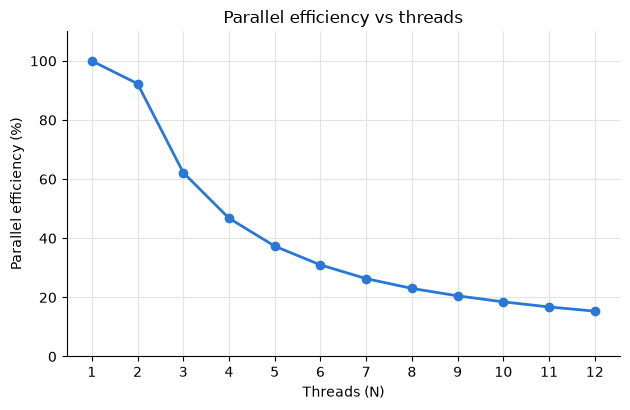

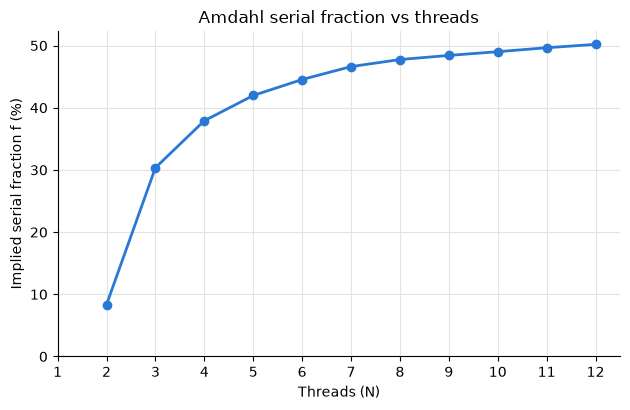

In [15]:


RUN_NAME = "run5 batch 2"   

threads = [r["threads"] for r in n_res]
speedup = [r["speedup"] for r in n_res]
efficiency = [r["efficiency"] for r in n_res]

f_threads = [n for n in threads if n > 1]
serial = [((n / s) - 1) / (n - 1) * 100 for n, s in zip(threads, speedup) if n > 1]

BLUE, GREY = "#2a78d6", "#8a8980"

def tidy(ax, ylabel, title):
    ax.set_xlabel("Threads (N)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(threads)
    ax.grid(True, color="#e4e3dc")
    ax.spines[["top", "right"]].set_visible(False)

# 1. Speedup vs ideal
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, threads, "--", color=GREY, label="Ideal (S = N)")
ax.plot(threads, speedup, "o-", color=BLUE, linewidth=2, label="Measured")
tidy(ax, "Speedup (T1 / TN)", "Speedup vs threads")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{RUN_NAME}_speedup.png", dpi=200); plt.show()

# 2. Efficiency
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, efficiency, "o-", color=BLUE, linewidth=2)
ax.set_ylim(0, 110)
tidy(ax, "Parallel efficiency (%)", "Parallel efficiency vs threads")
fig.tight_layout(); fig.savefig(f"{RUN_NAME}_efficiency.png", dpi=200); plt.show()

# 3. Serial fraction
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(f_threads, serial, "o-", color=BLUE, linewidth=2)
ax.set_ylim(bottom=0)
tidy(ax, "Implied serial fraction f (%)", "Amdahl serial fraction vs threads")
fig.tight_layout(); fig.savefig(f"{RUN_NAME}_serial_fraction.png", dpi=200); plt.show()